In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
from pathlib import Path
import numpy as np
import h5py
import matplotlib.pyplot as plt
from turbos.sim.vpic.vpic import VPIC, load_info
from turbos.filter import kfilter
from turbos.pressure_strain import pressure_strain

In [4]:
from turbos.sim.vpic.vpic import VPIC

run = VPIC(
    info_file="/work/space_plasma/users/goodwill/KH/info",
    data_dirs={
        "fields": "/lustre/scratch/goodwill/KH/field_hdf5",
        "hydro": "/lustre/scratch/goodwill/KH/hydro_hdf5",
    },
)

# ds = run.load_step(
#     480000,
#     ["B", "E", "ne", "ni", "Je", "ue", "ui", "Te", "Pe"],
# )

In [5]:
# print(ds.info)
print(run.nx, run.ny, run.nz)  # 1200, 2400, 1
print(run.lx, run.ly, run.lz)  # 125, 250, 0.1041667 — in d_e
print(run.dx, run.dy, run.dz)  # ≈ 0.1041667 each

1200 2400 1
125.0 250.0 0.1041667
0.1041667 0.1041667 0.1041667


In [6]:
# import xarray as xr
# from pathlib import Path

# # ds.close()

# results = []
# kf = 5

# t = [140000, 240000, 320000, 480000]

# for i in range(4):
#     print(f"Processing timestep {t[i]}")

#     ds = run.load_step(t[i], ['Pe', 'ue', 'Pi', 'ui'])
#     # print(ds)

#     Pe = kfilter(ds['Pe'], kf)
#     ue = kfilter(ds['ue'], kf)
#     Pi = kfilter(ds['Pi'], kf)
#     ui = kfilter(ds['ui'], kf)

#     pse = pressure_strain(Pe, ue)
#     psi = pressure_strain(Pi, ui)

#     ds_ps = xr.Dataset({
#         'PiD_e': pse['PiD'],
#         'pth_e': pse['pth'],
#         'PiD_i': psi['PiD'],
#         'pth_i': psi['pth'],
#     })

#     # Save normalized time as dimension coordinate
#     ds_ps = ds_ps.expand_dims(
#         time=[ds.attrs['time']]
#     )

#     # Save additional time information
#     ds_ps = ds_ps.assign_coords(
#         time_simulation=('time', [ds.attrs['time_simulation']]),
#         step=('time', [ds.attrs['step']])
#     )
#     results.append(ds_ps)

# # Combine all timesteps
# ds_all = xr.concat(results, dim='time')

# # Save as NetCDF
# ds_all.attrs['kf'] = kf
# path = Path("~/turbos/projects/KHI_2D/data/PS.nc").expanduser()
# ds_all.to_netcdf(path, mode="w")

In [7]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

ds_ps = xr.open_dataset("~/turbos/projects/KHI_2D/data/PS.nc")
print(ds_ps)
kf = 5

t = [140000, 240000, 320000, 480000]

# Your four VPIC output timesteps
times = np.asarray(t[:4])

stride = 8  # Sample every 8th grid point in each direction

def component(da, name):
    """Select vector component without retaining scalar coordinates."""

    dim = next(d for d in ("c", "comp") if d in da.dims)

    if name in da[dim].values:
        return da.sel({dim: name}, drop=True)

    return da.isel(
        {dim: {"x": 0, "y": 1, "z": 2}[name]},
        drop=True
    )


velocities = []

for ti in times:
    ds = run.load_step(ti, ["ui"])
    ui = ds["ui"]

    # Apply the same low-pass filter used for pressure-strain
    ui = kfilter(ui, 4)

    ds_v = xr.Dataset({
        "V_M": component(ui, "y"),
        "V_N": component(ui, "x")
    })

    ds_v = ds_v.isel(
        x=slice(None, None, stride),
        y=slice(None, None, stride)
    )

    velocities.append(
        ds_v.expand_dims(time=[ti]).load()
    )

ds_v = xr.concat(velocities, dim="time")

<xarray.Dataset> Size: 277MB
Dimensions:          (time: 4, x: 1200, y: 2400)
Coordinates:
  * time             (time) float64 32B 41.25 70.71 94.28 141.4
    time_simulation  (time) float64 32B ...
    step             (time) int64 32B ...
  * x                (x) float64 10kB 0.0 0.1042 0.2083 ... 124.7 124.8 124.9
  * y                (y) float64 19kB 0.0 0.1042 0.2083 ... 249.7 249.8 249.9
    j                <U1 4B ...
    i                <U1 4B ...
    c                <U1 4B ...
Data variables:
    PiD_e            (time, x, y) float64 92MB ...
    pth_e            (time, x, y) float32 46MB ...
    PiD_i            (time, x, y) float64 92MB ...
    pth_i            (time, x, y) float32 46MB ...
Attributes:
    kf:       5


In [8]:
ds_ps["PS_e"] = ds_ps["PiD_e"] + ds_ps["pth_e"]
ds_ps["PS_i"] = ds_ps["PiD_i"] + ds_ps["pth_i"]

ds_ps["PiD_tot"] = ds_ps["PiD_e"] + ds_ps["PiD_i"]
ds_ps["pth_tot"] = ds_ps["pth_e"] + ds_ps["pth_i"]
ds_ps["PS_tot"] = ds_ps["PS_e"] + ds_ps["PS_i"]

In [9]:
def velocity_binned_mean(
    vM, vN, Q,
    bins=40,
    min_count=5,
    percentile=(1, 99)
):
    vM = np.asarray(vM).ravel()
    vN = np.asarray(vN).ravel()
    Q = np.asarray(Q).ravel()

    # Remove invalid data
    valid = (
        np.isfinite(vM)
        & np.isfinite(vN)
        & np.isfinite(Q)
    )

    vM = vM[valid]
    vN = vN[valid]
    Q = Q[valid]

    if len(Q) == 0:
        raise ValueError("No finite samples available")

    # Remove event-average velocity
    vM = vM - np.mean(vM)
    vN = vN - np.mean(vN)

    # Normalize each velocity coordinate
    vM /= max(np.max(np.abs(vM)), np.finfo(float).tiny)
    vN /= max(np.max(np.abs(vN)), np.finfo(float).tiny)

    # Remove extreme Q values
    qlo, qhi = np.percentile(Q, percentile)

    keep = (Q >= qlo) & (Q <= qhi)

    vM = vM[keep]
    vN = vN[keep]
    Q = Q[keep]

    # Normalize energy conversion
    Q = Q / max(np.max(np.abs(Q)), np.finfo(float).tiny)

    edges = np.linspace(-1, 1, bins + 1)

    counts, _, _ = np.histogram2d(
        vM, vN, bins=[edges, edges]
    )

    weighted, _, _ = np.histogram2d(
        vM, vN,
        bins=[edges, edges],
        weights=Q
    )

    with np.errstate(divide="ignore", invalid="ignore"):
        mean_Q = weighted / counts

    mean_Q[counts < min_count] = np.nan

    return edges, mean_Q.T, counts.T

In [21]:
fields = [
    ["PiD_i", "PiD_e", "PiD_tot"],
    ["pth_i", "pth_e", "pth_tot"],
    ["PS_i",  "PS_e",  "PS_tot"],
]

time_idx = 1

vM = ds_v["V_M"].isel(time=time_idx).values.ravel()
vN = ds_v["V_N"].isel(time=time_idx).values.ravel()

def get_samples(var):
    return ds_ps[var].isel(
        time=time_idx,
        x=slice(None, None, stride),
        y=slice(None, None, stride)
    ).values.ravel()

print("vM:", vM.shape)
print("vN:", vN.shape)
print("PiD_i:", get_samples("PiD_i").shape)

vM: (45000,)
vN: (45000,)
PiD_i: (45000,)


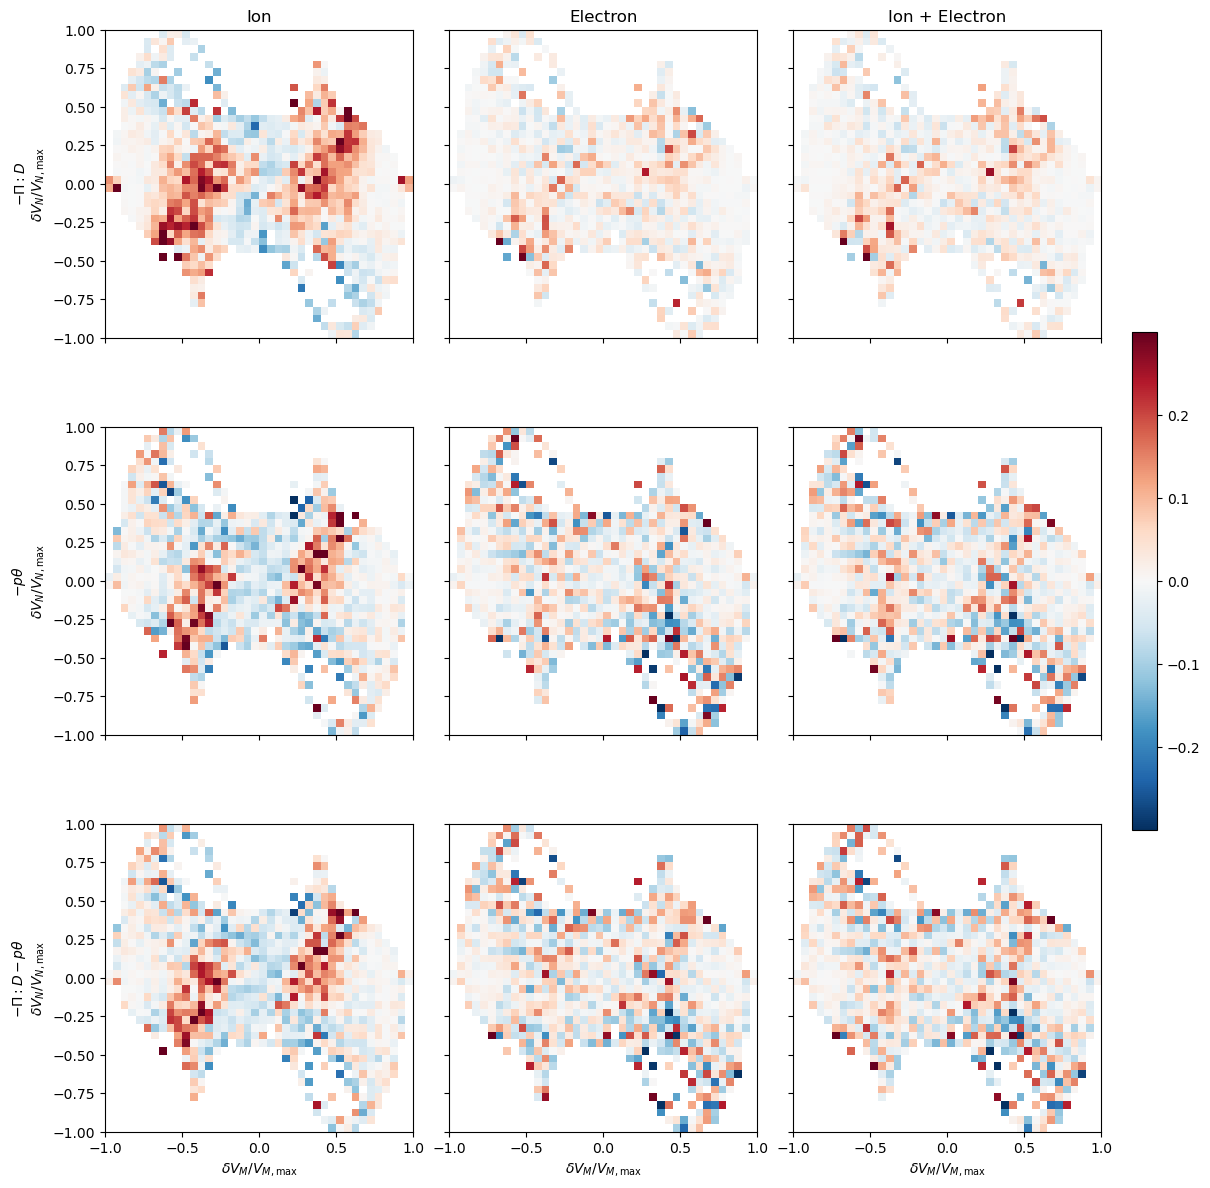

In [23]:
fig, ax = plt.subplots(
    3, 3,
    figsize=(12, 12),
    sharex=True,
    sharey=True,
    layout="constrained"
)

titles = ["Ion", "Electron", "Ion + Electron"]

row_labels = [
    r"$-\Pi:D$",
    r"$-p\theta$",
    r"$-\Pi:D-p\theta$"
]

for row in range(3):
    for col in range(3):

        var = fields[row][col]

        edges, Qmean, counts = velocity_binned_mean(
            vM, vN, get_samples(var),
            bins=40,
            min_count=5
        )

        im = ax[row, col].pcolormesh(
            edges,
            edges,
            Qmean,
            cmap="RdBu_r",
            norm=TwoSlopeNorm(vcenter=0, vmin=-3e-1, vmax=3e-1),
            shading="auto"
        )

        ax[row, col].set_aspect("equal")

        if row == 0:
            ax[row, col].set_title(titles[col])

        if col == 0:
            ax[row, col].set_ylabel(
                row_labels[row] + "\n" +
                r"$\delta V_N / V_{N,\max}$"
            )

        if row == 2:
            ax[row, col].set_xlabel(
                r"$\delta V_M / V_{M,\max}$"
            )

cbar = fig.colorbar(
    im,
    ax=ax,
    location="right",
    fraction=0.025,
    pad=0.02,
    shrink=0.7
)


fig.savefig(
    "PS_2D.png",
    bbox_inches="tight"
)

plt.show()